# RAG: Baseline Bi-Encoder Retrieval vs. Cross-Encoder Re-Ranking

**Document:** RFC 6749 — *The OAuth 2.0 Authorization Framework* (IETF, 76 pages). A normative
technical specification full of `MUST` / `MUST NOT` requirements, role-specific rules
(client vs. authorization server, public vs. confidential clients) and exceptions spread across
sections — a good stress test for retrieval.

**Pipelines (same chunked corpus for both):**

| | Pipeline 1 — Baseline | Pipeline 2 — Re-ranking |
|---|---|---|
| Retrieve | Bi-encoder (`all-MiniLM-L6-v2`) + FAISS inner product → Top 10 | same Top 10 |
| Select | Top 3 by cosine similarity | Cross-encoder (`ms-marco-MiniLM-L-6-v2`) scores all 10 (query, chunk) pairs → Top 3 |
| Generate | Local LLM (Qwen2.5-7B-Instruct via Ollama), shared prompt → **Answer 1** | same LLM, identical prompt → **Answer 2** |

**Notebook outline**
1. Setup & configuration
2. Loading and cleaning the PDF
3. Section-aware chunking
4. Bi-encoder index (FAISS)
5. Pipeline 1 — baseline retrieval
6. Pipeline 2 — cross-encoder re-ranking
7. Shared prompt + LLM generation
8. Evaluation query set (labelled failure categories) and rank-shift analysis
9. Failure-case deep dives: top-10 tables and Answer 1 vs. Answer 2
10. Latency profiling (GPU and CPU)
11. Scaling experiment: why not cross-encode the whole corpus?
12. Saving results

## 1. Setup & configuration

In [1]:
# Standard library
import hashlib
import json
import os
import re
import statistics
import time
from pathlib import Path

# Third-party
import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
import torch
import ollama
from sentence_transformers import CrossEncoder, SentenceTransformer

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# ---- Configuration --------------------------------------------------------
PDF_PATH = Path("data/rfc6749_oauth2.pdf")
BI_ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"     # dense bi-encoder (384-d)
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"    # re-ranker named in the assignment
LLM_MODEL = "qwen2.5:7b-instruct"     # local open-weights LLM served by Ollama (4-bit, ~4.7 GB)
LLM_OPTIONS = {"temperature": 0, "seed": 42, "num_ctx": 4096, "num_predict": 300}

TOP_K = 10          # candidates retrieved by the bi-encoder
TOP_N = 3           # chunks passed to the LLM
MAX_WORDS = 120     # chunk size budget (keeps chunks under MiniLM's 256-token limit)

RESULTS_DIR = Path("results")
FIG_DIR = RESULTS_DIR / "figures"
LLM_CACHE_PATH = RESULTS_DIR / "llm_answers.json"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
print("torch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only")

torch 2.14.1+cu130 | device: cuda | NVIDIA GeForce RTX 5050 Laptop GPU


In [2]:
# The LLM runs locally through Ollama (https://ollama.com): start the server with `ollama serve`
# and download the model once with `ollama pull qwen2.5:7b-instruct`. No cloud service or internet
# connection is needed at generation time.
llm_client = ollama.Client(host="http://127.0.0.1:11434")
try:
    installed = [m.model for m in llm_client.list().models]
    if LLM_MODEL not in installed:
        print(f"Pulling {LLM_MODEL} ...")
        llm_client.pull(LLM_MODEL)
    # warm-up: loads the weights into GPU memory so the first timed call isn't a cold start
    llm_client.generate(model=LLM_MODEL, prompt="Reply with OK.", options=LLM_OPTIONS, keep_alive="30m")
    print(f"Ollama ready: {LLM_MODEL}")
except Exception as e:  # no server running -> fall back to cached answers only
    llm_client = None
    print(f"Ollama not reachable ({type(e).__name__}); only cached answers will be used")

Ollama ready: qwen2.5:7b-instruct


## 2. Loading and cleaning the PDF

The RFC is a fixed-width text document rendered to PDF. Each page carries a running header
(`RFC 6749  OAuth 2.0  October 2012`) and footer (`Hardt  Standards Track  [Page N]`) that would
otherwise pollute chunks, so they are removed. Two more clean-ups:

* **Page-break joins** – a paragraph that continues onto the next page is re-joined (a page break
  only counts as a paragraph break if the previous line ended a sentence).
* **ASCII art** – the protocol-flow figures are drawn with `+----+`, `|` and `--->`; runs of these
  characters are stripped so they don't waste tokens. Curly quotes from the PDF are normalised.

In [3]:
HEADER_RE = re.compile(r"^RFC 6749\s+OAuth 2\.0\s+October 2012$")
FOOTER_RE = re.compile(r"^Hardt\s+Standards Track\s+\[Page \d+\]$")
BOXART_RE = re.compile(r"[-+|=<>/\\]{3,}|(?<=\s)\|(?=\s|$)|^\|")
QUOTES = str.maketrans({"’": "'", "‘": "'", "“": '"', "”": '"'})


def load_clean_lines(pdf_path):
    """Return (lines, page_numbers) for the whole PDF with headers/footers removed."""
    lines, pages = [], []
    doc = pymupdf.open(pdf_path)
    for pno, page in enumerate(doc, start=1):
        page_lines = []
        for ln in page.get_text("text", sort=True).split("\n"):
            if HEADER_RE.match(ln.strip()) or FOOTER_RE.match(ln.strip()):
                continue
            page_lines.append(BOXART_RE.sub(" ", ln.translate(QUOTES)).rstrip())
        # trim blank lines left behind by the removed header/footer
        while page_lines and not page_lines[0].strip():
            page_lines.pop(0)
        while page_lines and not page_lines[-1].strip():
            page_lines.pop()
        # keep a paragraph break at the page boundary only if the last line ended a sentence
        if lines and re.search(r"[.:)\]]$", lines[-1]):
            lines.append(""); pages.append(pno)
        lines += page_lines
        pages += [pno] * len(page_lines)
    return lines, pages, len(doc)


lines, line_pages, n_pages = load_clean_lines(PDF_PATH)
print(f"{n_pages} pages -> {len(lines)} cleaned lines")
print("\n".join(lines[:16]))

76 pages -> 3375 cleaned lines
Internet Engineering Task Force (IETF)                     D. Hardt, Ed.
Request for Comments: 6749                                     Microsoft
Obsoletes: 5849                                             October 2012
Category: Standards Track
ISSN: 2070-1721


                 The OAuth 2.0 Authorization Framework

Abstract

   The OAuth 2.0 authorization framework enables a third-party
   application to obtain limited access to an HTTP service, either on
   behalf of a resource owner by orchestrating an approval interaction
   between the resource owner and the HTTP service, or by allowing the
   third-party application to obtain access on its own behalf.  This


## 3. Section-aware chunking

RFC sections are numbered (`4.1.2.`, `10.12.`, `Appendix A.`, `A.1.`), so chunks never cross a
section boundary. Within a section, paragraphs are packed greedily up to `MAX_WORDS` words;
an over-long paragraph is split at sentence boundaries; a short trailing paragraph is repeated
at the start of the next chunk as overlap. Every chunk is prefixed with its section number and
title so both encoders know where the text comes from.

Boilerplate with no rules in it (status memo, copyright, table of contents, references,
acknowledgements, author address) is not indexed. The IANA-registry sections (§11) and the ABNF
syntax appendix are kept on purpose: they repeat parameter names such as `refresh_token`,
`scope`, `redirect_uri` many times, which makes them realistic *lexical distractors*.

The chunk budget matters: `all-MiniLM-L6-v2` truncates input at **256 word-pieces**, and the
cross-encoder at 512 for query + passage. With 120 words, almost no chunk is truncated (checked below).

In [4]:
HEADING_RE = re.compile(r"^((?:\d+(?:\.\d+)*\.)|(?:Appendix [A-Z]\.)|(?:[A-Z]\.\d+(?:\.\d+)*\.))\s+(\S.*)$")
DROP_SECTIONS_RE = re.compile(r"^(12(\.\d+)*|C)$")       # 12 = References, C = Acknowledgements
SENTENCE_SPLIT_RE = re.compile(r"(?<=[.!?])\s+(?=[A-Z\"(])")


def split_sections(lines, pages):
    """Group cleaned lines into numbered sections. Everything before 'Abstract'
    and the TOC/boilerplate between the abstract and Section 1 are skipped."""
    sections, cur = [], None
    for ln, pno in zip(lines, pages):
        m = HEADING_RE.match(ln)
        if ln == "Abstract":
            cur = {"section": "Abstract", "title": "Abstract", "page": pno, "lines": []}
            sections.append(cur)
        elif ln.startswith(("Status of This Memo", "Author's Address")):
            cur = None                                   # boilerplate until the next heading
        elif m:                                          # TOC lines are indented, so they never match
            num = m.group(1).rstrip(".").replace("Appendix ", "")
            cur = {"section": num, "title": m.group(2).strip(), "page": pno, "lines": []}
            sections.append(cur)
        elif cur is not None:
            cur["lines"].append(ln)
    return [s for s in sections if not DROP_SECTIONS_RE.match(s["section"])]


def to_paragraphs(sec_lines):
    """Blank-line separated paragraphs, each re-flowed onto one line."""
    paras, buf = [], []
    for ln in sec_lines + [""]:
        if ln.strip():
            buf.append(ln.strip())
        elif buf:
            paras.append(" ".join(buf)); buf = []
    return paras


def chunk_sections(sections, max_words=MAX_WORDS):
    chunks = []
    for s in sections:
        # 1) units = paragraphs, with over-long ones broken into groups of whole sentences
        units = []
        for p in to_paragraphs(s["lines"]):
            if len(p.split()) <= max_words:
                units.append(p); continue
            cur = ""
            for sent in SENTENCE_SPLIT_RE.split(p):
                if cur and len((cur + " " + sent).split()) > max_words:
                    units.append(cur); cur = sent
                else:
                    cur = (cur + " " + sent).strip()
            if cur:
                units.append(cur)
        # 2) greedy packing of units into chunks, carrying a short last unit over as overlap
        window = []
        for u in units:
            if window and len(" ".join(window + [u]).split()) > max_words:
                chunks.append((s, window))
                window = [window[-1]] if len(window[-1].split()) <= 40 else []
            window.append(u)
        if window:
            chunks.append((s, window))
    return [{"chunk_id": i, "section": s["section"], "title": s["title"], "page": s["page"],
             "text": f"Section {s['section']} {s['title']}\n" + "\n".join(w)}
            for i, (s, w) in enumerate(chunks)]


sections = split_sections(lines, line_pages)
chunks = chunk_sections(sections)
chunk_df = pd.DataFrame(chunks)
chunk_df["words"] = chunk_df.text.str.split().str.len()
print(f"{len(sections)} sections -> {len(chunks)} chunks")
chunk_df.words.describe().round(1).to_frame("words per chunk").T

116 sections -> 228 chunks


,count,mean,std,min,25%,50%,75%,max
words per chunk,228.0,84.8,31.7,15.0,63.0,93.0,110.0,142.0


In [5]:
# Example chunk: the authorization-code rules of Section 4.1.2
print(next(c["text"] for c in chunks if c["section"] == "4.1.2" and "more than once" in c["text"]))

Section 4.1.2 Authorization Response
code REQUIRED.  The authorization code generated by the authorization server.  The authorization code MUST expire shortly after it is issued to mitigate the risk of leaks.  A maximum authorization code lifetime of 10 minutes is RECOMMENDED.  The client MUST NOT use the authorization code more than once.  If an authorization code is used more than once, the authorization server MUST deny the request and SHOULD revoke (when possible) all tokens previously issued based on that authorization code.  The authorization code is bound to the client identifier and redirection URI.
state REQUIRED if the "state" parameter was present in the client authorization request.  The exact value received from the client.


## 4. Bi-encoder index (FAISS)

The bi-encoder embeds every chunk **independently** into a 384-d vector, once, offline. Vectors are
L2-normalised, so inner product in `IndexFlatIP` equals cosine similarity. A flat (exact) index is
fine for a few hundred chunks.

In [6]:
bi_encoder = SentenceTransformer(BI_ENCODER_NAME, device=DEVICE)
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME, device=DEVICE)

# How many chunks exceed each model's input limit (would be silently truncated)?
tok = bi_encoder.tokenizer
token_lens = np.array([len(tok(c["text"])["input_ids"]) for c in chunks])
print(f"bi-encoder max_seq_length = {bi_encoder.max_seq_length}; "
      f"chunk tokens: median {np.median(token_lens):.0f}, max {token_lens.max()}, "
      f"> {bi_encoder.max_seq_length}: {(token_lens > bi_encoder.max_seq_length).sum()} of {len(chunks)}")

t0 = time.perf_counter()
chunk_embeddings = bi_encoder.encode([c["text"] for c in chunks], batch_size=64,
                                     normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
index = faiss.IndexFlatIP(chunk_embeddings.shape[1])
index.add(chunk_embeddings)
INDEX_BUILD_S = time.perf_counter() - t0
print(f"Indexed {index.ntotal} chunks, dim={chunk_embeddings.shape[1]}, build time {INDEX_BUILD_S:.2f}s ({DEVICE})")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (263 > 256). Running this sequence through the model will result in indexing errors


bi-encoder max_seq_length = 256; chunk tokens: median 136, max 281, > 256: 2 of 228


Indexed 228 chunks, dim=384, build time 0.43s (cuda)


## 5. Pipeline 1 — baseline retrieval

In [7]:
def baseline_retrieve(query, k=TOP_K, encoder=None):
    """Embed the query with the bi-encoder and return the top-k chunks by cosine similarity.
    Returns a list of dicts ordered by rank."""
    encoder = encoder or bi_encoder
    q = encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
    scores, ids = index.search(q, k)
    return [{"chunk_id": int(i), "bi_rank": r, "bi_score": float(s)}
            for r, (i, s) in enumerate(zip(ids[0], scores[0]), start=1)]


def pipeline1(query):
    """Baseline: top-10 by cosine similarity, keep the first 3."""
    candidates = baseline_retrieve(query)
    return candidates, candidates[:TOP_N]


cands, top3 = pipeline1("Can an authorization code be used more than once?")
pd.DataFrame([{**c, "section": chunks[c["chunk_id"]]["section"],
               "title": chunks[c["chunk_id"]]["title"]} for c in cands])

,chunk_id,bi_rank,bi_score,section,title
0,163,1,0.754902,10.5,Authorization Codes
1,78,2,0.637821,4.1.2,Authorization Response
2,15,3,0.597052,1.3.1,Authorization Code
3,156,4,0.560913,10.2,Client Impersonation
4,73,5,0.560324,4.1,Authorization Code Grant
5,14,6,0.535579,1.3.1,Authorization Code
6,108,7,0.514958,4.3.1,Authorization Request and Response
7,66,8,0.514368,3.2.1,Client Authentication
8,151,9,0.505885,9,Native Applications
9,70,10,0.505209,4.1,Authorization Code Grant


## 6. Pipeline 2 — cross-encoder re-ranking

The cross-encoder reads the query and the chunk **together** in one transformer pass, so every
query token can attend to every chunk token. It outputs a single relevance score per pair. It cannot
pre-compute anything for the corpus, which is why it only sees the 10 candidates from Pipeline 1.

In [8]:
def rerank(query, candidates, model=None):
    """Score every (query, chunk) pair with the cross-encoder and sort descending."""
    model = model or cross_encoder
    pairs = [(query, chunks[c["chunk_id"]]["text"]) for c in candidates]
    ce_scores = model.predict(pairs, batch_size=len(pairs), show_progress_bar=False)
    reranked = [{**c, "ce_score": float(s)} for c, s in zip(candidates, ce_scores)]
    reranked.sort(key=lambda c: c["ce_score"], reverse=True)
    for r, c in enumerate(reranked, start=1):
        c["ce_rank"] = r
    return reranked


def pipeline2(query):
    """Re-ranking: the same top-10 candidates, re-sorted by cross-encoder score, keep the first 3."""
    candidates = baseline_retrieve(query)
    reranked = rerank(query, candidates)
    return reranked, reranked[:TOP_N]


rr, top3_rr = pipeline2("Can an authorization code be used more than once?")
pd.DataFrame([{**c, "section": chunks[c["chunk_id"]]["section"]} for c in rr])[
    ["ce_rank", "bi_rank", "chunk_id", "section", "ce_score", "bi_score"]]

,ce_rank,bi_rank,chunk_id,section,ce_score,bi_score
0,1,2,78,4.1.2,9.566240,0.637821
1,2,1,163,10.5,5.767750,0.754902
2,3,3,15,1.3.1,1.605419,0.597052
3,4,9,151,9,0.691611,0.505885
4,5,6,14,1.3.1,0.494240,0.535579
5,6,10,70,4.1,-0.914434,0.505209
6,7,5,73,4.1,-1.402602,0.560324
7,8,7,108,4.3.1,-3.114764,0.514958
8,9,8,66,3.2.1,-3.351757,0.514368
9,10,4,156,10.2,-4.585015,0.560913


## 7. Shared prompt and LLM generation

Both pipelines use **exactly the same prompt template** — only the three context chunks differ.
The LLM is told to answer only from the context and to say so when the context is insufficient,
so differences between Answer 1 and Answer 2 come from retrieval, not from the prompt.

The generator is **Qwen2.5-7B-Instruct** (4-bit quantised) running locally through Ollama on the same
GPU. Temperature 0 and a fixed seed make the outputs repeatable.

Responses are cached in `results/llm_answers.json` (keyed by a hash of model + prompt), so the notebook
can be re-executed without Ollama installed; the cache also stores the measured generation time.

In [9]:
PROMPT_TEMPLATE = """You are a helpful assistant answering questions about RFC 6749 (The OAuth 2.0 Authorization Framework).

Answer the question using ONLY the context passages below.
- Be concise (at most 4 sentences).
- When the context states a requirement, keep its exact strength (MUST, MUST NOT, SHOULD, SHOULD NOT, MAY, RECOMMENDED).
- Cite the section numbers you relied on, e.g. (Section 4.1.2).
- If the context does not contain the answer, reply: "The provided context does not answer this question."

Context:
{context}

Question: {question}
Answer:"""


def build_prompt(question, selected):
    context = "\n\n".join(f"[{i}] {chunks[c['chunk_id']]['text']}" for i, c in enumerate(selected, start=1))
    return PROMPT_TEMPLATE.format(context=context, question=question)


llm_cache = json.loads(LLM_CACHE_PATH.read_text()) if LLM_CACHE_PATH.exists() else {}


def generate(prompt):
    """Generate an answer with the local LLM (deterministic options). Cached by hash(model + prompt).
    Returns (answer_text, latency_seconds), or (None, None) if neither cache nor Ollama is available."""
    key = hashlib.sha256((LLM_MODEL + "\n" + prompt).encode()).hexdigest()
    if key in llm_cache:
        return llm_cache[key]["answer"], llm_cache[key]["latency_s"]
    if llm_client is None:
        return None, None
    t0 = time.perf_counter()
    resp = llm_client.chat(model=LLM_MODEL, messages=[{"role": "user", "content": prompt}],
                           options=LLM_OPTIONS, keep_alive="30m")
    latency = time.perf_counter() - t0
    answer = resp.message.content.strip()
    llm_cache[key] = {"model": LLM_MODEL, "answer": answer, "latency_s": latency,
                      "output_tokens": resp.eval_count, "prompt_tokens": resp.prompt_eval_count}
    LLM_CACHE_PATH.write_text(json.dumps(llm_cache, indent=1))
    return answer, latency


def answer_both(question):
    """Run both pipelines end-to-end and return Answer 1, Answer 2 and their contexts."""
    cand, sel1 = pipeline1(question)
    reranked = rerank(question, cand)
    sel2 = reranked[:TOP_N]
    a1, l1 = generate(build_prompt(question, sel1))
    a2, l2 = generate(build_prompt(question, sel2))
    return {"question": question, "answer1": a1, "answer2": a2,
            "sections1": [chunks[c["chunk_id"]]["section"] for c in sel1],
            "sections2": [chunks[c["chunk_id"]]["section"] for c in sel2],
            "llm_latency_1": l1, "llm_latency_2": l2}


print(build_prompt("Can an authorization code be used more than once?", top3)[:1200], "...")

You are a helpful assistant answering questions about RFC 6749 (The OAuth 2.0 Authorization Framework).

Answer the question using ONLY the context passages below.
- Be concise (at most 4 sentences).
- When the context states a requirement, keep its exact strength (MUST, MUST NOT, SHOULD, SHOULD NOT, MAY, RECOMMENDED).
- Cite the section numbers you relied on, e.g. (Section 4.1.2).
- If the context does not contain the answer, reply: "The provided context does not answer this question."

Context:
[1] Section 10.5 Authorization Codes
Authorization codes MUST be short lived and single-use.  If the authorization server observes multiple attempts to exchange an authorization code for an access token, the authorization server SHOULD attempt to revoke all access tokens already granted based on the compromised authorization code.
If the client can be authenticated, the authorization servers MUST authenticate the client and ensure that the authorization code was issued to the same client.

[2]

## 8. Evaluation query set and rank-shift analysis

To measure retrieval objectively, every query has one or more hand-labelled **gold phrases**:
verbatim fragments of the RFC sentences that a careful reader would cite as the answer. A chunk is
"gold" if it contains any of them (this keeps labels valid even if chunk ids change). Passages that
only mention the topic in passing (e.g. the `state` parameter saying it "SHOULD be used for
preventing cross-site request forgery") are deliberately *not* gold — they don't answer the question. Each query was written for one
failure category from the assignment:

| Category | Idea | Example |
|---|---|---|
| `keyword_trap` | user vocabulary ≠ RFC vocabulary; lexical overlap with the wrong passage | "one-time login code" vs. *authorization code* |
| `exception` | general rule is easy to find, the specific condition / corner case is elsewhere | redirect_uri required *only if* it was sent earlier |
| `negation` | "not allowed / MUST NOT / which clients cannot …" | implicit grant MUST NOT issue a refresh token |
| `buried` | specific detail inside a long section, outranked by generic overview chunks | refresh-token binding to the client |

For every query, we record the rank of the gold chunk in Pipeline 1 (bi-encoder rank, also
searched beyond the top 10) and in Pipeline 2 (cross-encoder rank among the 10 candidates).

In [10]:
QUERIES = [
    # (id, category, query, gold phrase(s))
    ("K1", "keyword_trap", "How long should a one-time login code stay valid?",
     ["maximum authorization code lifetime of 10 minutes"]),
    ("K2", "keyword_trap", "How do I stop attackers from tricking users into clicking a hidden button on the approval page?",
     ["Clickjacking"]),
    ("K3", "keyword_trap", "How can a website stop another site from forging the callback to its redirect page?",
     ["The client MUST implement CSRF protection for its redirection URI", "binding value used for CSRF protection"]),
    ("K4", "keyword_trap", "What does the server send back when the user declines the permission request?",
     ["access_denied"]),
    ("K5", "keyword_trap", "Is it safe to let a phone app keep a secret key for authenticating itself?",
     ["MUST NOT issue client passwords or other client credentials to native application",
      "native application's inability to keep client credentials confidential",
      "any client authentication credentials included in the application can be extracted"]),
    ("K6", "keyword_trap", "How should an app installed on a desktop receive the response from the login page?",
     ["Native applications are clients installed and executed on the device",
      "the native application can capture the response from the authorization server"]),
    ("K7", "keyword_trap", "Should a browser or proxy be allowed to store the token response?",
     ["no-store"]),
    ("K8", "keyword_trap", "What is the token's time to live field called?",
     ["The lifetime in seconds of the access token"]),
    ("E1", "exception", "What happens if an authorization code is used twice?",
     ["used more than once, the authorization server MUST deny the request",
      "observes multiple attempts to exchange an authorization code"]),
    ("E2", "exception", "Does the client credentials grant give back a refresh token?",
     ["A refresh token SHOULD NOT be included"]),
    ("E3", "exception", "When must the authorization server not send the user back to the client after an error?",
     ["MUST NOT automatically redirect"]),
    ("E4", "exception", "Is redirect_uri needed when exchanging the code for a token?",
     ['REQUIRED, if the "redirect_uri" parameter was included in the authorization request',
      'ensure that the "redirect_uri" parameter is present']),
    ("E5", "exception", "Can the server hand out a new refresh token when the client refreshes, and what happens to the old one?",
     ["MUST discard the old refresh token"]),
    ("E6", "exception", "Can a native app installation ever be given its own client password?",
     ["for a specific installation of a native application client"]),
    ("E7", "exception", "When is the scope parameter required in the token response?",
     ["OPTIONAL, if identical to the scope requested by the client; otherwise, REQUIRED"]),
    ("E8", "exception", "Which status code does the token endpoint use for invalid_client when the client used the Authorization header?",
     ["MUST respond with an HTTP 401"]),
    ("N1", "negation", "Is the implicit grant allowed to issue a refresh token?",
     ["The authorization server MUST NOT issue a refresh token.",
      "does not support the issuance of refresh tokens",
      "When using the implicit grant type flow, a refresh token is not returned"]),
    ("N2", "negation", "Is it allowed to put the client secret in the request URI?",
     ["MUST NOT be included in the request URI"]),
    ("N3", "negation", "Can a refresh request ask for more scope than originally granted?",
     ["MUST NOT include any scope not originally granted"]),
    ("N4", "negation", "Is the client allowed to keep the user's password after getting a token with the password grant?",
     ["MUST discard the credentials once an access token has been obtained"]),
    ("N5", "negation", "Can the authorization endpoint URI contain a fragment?",
     ["MUST NOT include a fragment component"]),
    ("N6", "negation", "Can a parameter appear more than once in a request?",
     ["MUST NOT be included more than once"]),
    ("N7", "negation", "Which clients are not allowed to use the password grant?",
     ["only be used when there is a high degree of trust",
      "suitable in cases where the resource owner has a trust relationship with the client"]),
    ("N8", "negation", "Should the authorization server accept a redirect to any URI without registration?",
     ["MUST require the following clients to register their redirection endpoint"]),
    ("N9", "negation", "Are public clients required to authenticate at the token endpoint?",
     ["Confidential clients or other clients issued client credentials MUST authenticate",
      "MAY establish a client authentication method with public clients"]),
    ("B1", "buried", "Does OAuth define how the resource server validates an access token?",
     ["beyond the scope of this specification"]),
    ("B2", "buried", "What error code is returned when the requested scope is invalid?",
     ["invalid_scope"]),
    ("B3", "buried", "What is the risk of an open redirector at the redirect endpoint?",
     ["Open Redirectors"]),
    ("B4", "buried", "How should the client protect itself against redirect URI manipulation with authorization codes?",
     ["Authorization Code Redirection URI Manipulation"]),
    ("B5", "buried", "Why should refresh tokens be bound to the client they were issued to?",
     ["Because refresh tokens are typically long-lasting credentials",
      "MUST maintain the binding between a refresh token and the client",
      "MUST verify the binding between the refresh token and client identity"]),
    ("B6", "buried", "How can an attacker guess tokens and what entropy is needed?",
     ["probability of an attacker guessing generated tokens"]),
    ("B7", "buried", "What should the server do if the redirect URI in the authorization request doesn't match the registered one?",
     ["invalid redirection URI"]),
    ("B8", "buried", "What should be done when TLS isn't available for the redirect endpoint?",
     ["If TLS is not available"]),
    ("B9", "buried", "Can the authorization server issue a refresh token in the authorization code flow?",
     ["access token and optional refresh token"]),
]

# Sanity check: every gold phrase must exist in the indexed corpus
gold_chunks = {qid: {c["chunk_id"] for c in chunks if any(g in c["text"] for g in golds)}
               for qid, _, _, golds in QUERIES}
assert all(gold_chunks.values()), [q for q, g in gold_chunks.items() if not g]
print(len(QUERIES), "queries; gold chunks per query:", {q: sorted(g) for q, g in list(gold_chunks.items())[:6]}, "...")

34 queries; gold chunks per query: {'K1': [78], 'K2': [179, 180], 'K3': [176, 177], 'K4': [81, 84, 102, 105], 'K5': [39, 150, 151, 153], 'K6': [147, 148]} ...


In [11]:
def first_gold_rank(ranked_ids, gold_ids):
    """1-based rank of the first gold chunk in a ranked list of chunk ids (None if absent)."""
    return next((r for r, cid in enumerate(ranked_ids, start=1) if cid in gold_ids), None)


rows, runs = [], {}
for qid, cat, q, _ in QUERIES:
    full = baseline_retrieve(q, k=len(chunks))      # whole-corpus bi-encoder ranking
    cand = full[:TOP_K]
    reranked = rerank(q, cand)
    runs[qid] = {"candidates": cand, "reranked": reranked}
    g = gold_chunks[qid]
    b_rank = first_gold_rank([c["chunk_id"] for c in cand], g)
    r_rank = first_gold_rank([c["chunk_id"] for c in reranked], g)
    rows.append({
        "id": qid, "category": cat, "query": q,
        "gold_rank_full_corpus": first_gold_rank([c["chunk_id"] for c in full], g),
        "baseline_rank": b_rank, "reranked_rank": r_rank,
        "in_top3_baseline": b_rank is not None and b_rank <= TOP_N,
        "in_top3_reranked": r_rank is not None and r_rank <= TOP_N,
    })

eval_df = pd.DataFrame(rows)
# nullable integers: a missing rank stays <NA> instead of turning the column into floats
for col in ["gold_rank_full_corpus", "baseline_rank", "reranked_rank"]:
    eval_df[col] = eval_df[col].astype("Int64")


def outcome(r):
    if pd.isna(r.baseline_rank):
        return "recall miss (gold not in top 10)"
    if not r.in_top3_baseline and r.in_top3_reranked:
        return "PROMOTED into top 3"
    if r.in_top3_baseline and not r.in_top3_reranked:
        return "DEMOTED out of top 3"
    if r.in_top3_baseline:
        return "top 3 in both"
    return "outside top 3 in both"


eval_df["outcome"] = eval_df.apply(outcome, axis=1)
eval_df["shift"] = eval_df.apply(
    lambda r: (f"#{r.baseline_rank} -> #{r.reranked_rank}" if not pd.isna(r.baseline_rank)
               else f"#{r.gold_rank_full_corpus} in full corpus (not in top 10)"), axis=1)
eval_df[["id", "category", "query", "shift", "outcome"]]

,id,category,query,shift,outcome
0,K1,keyword_trap,How long should a one-time login code stay valid?,#2 -> #1,top 3 in both
1,K2,keyword_trap,How do I stop attackers from tricking users into clicking a hidden button on the approval page?,#1 -> #1,top 3 in both
2,K3,keyword_trap,How can a website stop another site from forging the callback to its redirect page?,#3 -> #4,DEMOTED out of top 3
3,K4,keyword_trap,What does the server send back when the user declines the permission request?,#17 in full corpus (not in top 10),recall miss (gold not in top 10)
4,K5,keyword_trap,Is it safe to let a phone app keep a secret key for authenticating itself?,#2 -> #3,top 3 in both
5,K6,keyword_trap,How should an app installed on a desktop receive the response from the login page?,#1 -> #2,top 3 in both
6,K7,keyword_trap,Should a browser or proxy be allowed to store the token response?,#6 -> #1,PROMOTED into top 3
7,K8,keyword_trap,What is the token's time to live field called?,#1 -> #2,top 3 in both
8,E1,exception,What happens if an authorization code is used twice?,#1 -> #1,top 3 in both
9,E2,exception,Does the client credentials grant give back a refresh token?,#21 in full corpus (not in top 10),recall miss (gold not in top 10)


In [12]:
def mrr(ranks):
    """Mean reciprocal rank within the top 10 (a miss counts as 0)."""
    return float(np.mean([0.0 if pd.isna(r) else 1 / r for r in ranks]))


summary = pd.DataFrame({
    "Pipeline 1 (bi-encoder)": {
        "Hit@1": (eval_df.baseline_rank.fillna(0) == 1).mean(),
        "Hit@3 (gold reaches the LLM)": eval_df.in_top3_baseline.mean(),
        "Recall@10": eval_df.baseline_rank.notna().mean(),
        "MRR@10": mrr(eval_df.baseline_rank),
    },
    "Pipeline 2 (+ cross-encoder)": {
        "Hit@1": (eval_df.reranked_rank.fillna(0) == 1).mean(),
        "Hit@3 (gold reaches the LLM)": eval_df.in_top3_reranked.mean(),
        "Recall@10": eval_df.reranked_rank.notna().mean(),   # same candidate pool -> identical by design
        "MRR@10": mrr(eval_df.reranked_rank),
    },
}).round(3)
display(summary)

by_cat = eval_df.groupby("category").agg(
    queries=("id", "count"),
    hit3_baseline=("in_top3_baseline", "sum"),
    hit3_reranked=("in_top3_reranked", "sum"),
    promoted=("outcome", lambda s: (s == "PROMOTED into top 3").sum()),
    recall_misses=("outcome", lambda s: (s == "recall miss (gold not in top 10)").sum()),
)
by_cat

,Pipeline 1 (bi-encoder),Pipeline 2 (+ cross-encoder)
Hit@1,0.412,0.647
Hit@3 (gold reaches the LLM),0.735,0.824
Recall@10,0.882,0.882
MRR@10,0.576,0.732


,queries,hit3_baseline,hit3_reranked,promoted,recall_misses
category,,,,,
buried,9,7,8,1,1
exception,8,6,7,1,1
keyword_trap,8,6,6,1,1
negation,9,6,7,2,1


### Rank-shift chart

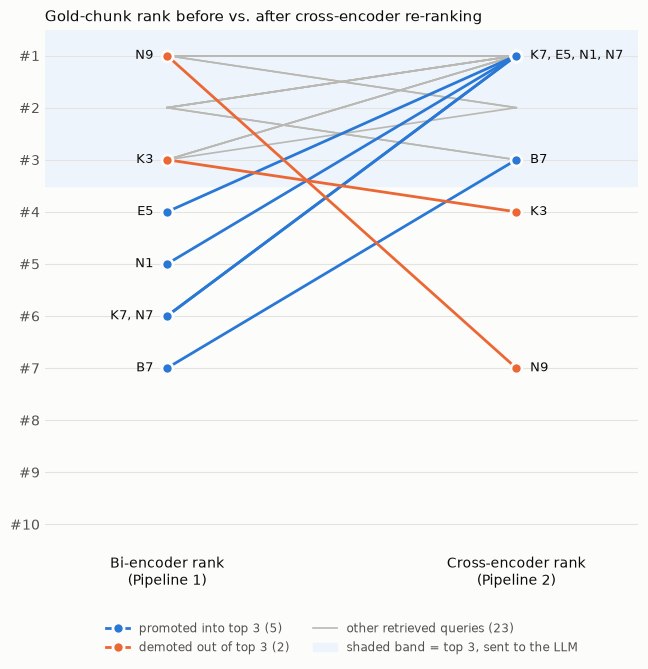

In [13]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
PROMOTED, DEMOTED, OTHER = "#2a78d6", "#eb6834", "#b9b8b2"

plot_df = eval_df[eval_df.baseline_rank.notna()].astype({"baseline_rank": int, "reranked_rank": int})
fig, ax = plt.subplots(figsize=(6.6, 6.8), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.axhspan(0.5, 3.5, color="#eef4fc", zorder=0)

promoted = plot_df[plot_df.outcome == "PROMOTED into top 3"]
demoted = plot_df[plot_df.outcome == "DEMOTED out of top 3"]
others = plot_df[~plot_df.outcome.isin(["PROMOTED into top 3", "DEMOTED out of top 3"])]
for _, r in others.iterrows():
    ax.plot([0, 1], [r.baseline_rank, r.reranked_rank], color=OTHER, lw=1.2, zorder=1)
for group, colour, label in [(promoted, PROMOTED, "promoted into top 3"), (demoted, DEMOTED, "demoted out of top 3")]:
    for k, (_, r) in enumerate(group.iterrows()):
        ax.plot([0, 1], [r.baseline_rank, r.reranked_rank], color=colour, lw=2, marker="o", ms=8,
                markeredgecolor=SURFACE, markeredgewidth=2, zorder=3,
                label=f"{label} ({len(group)})" if k == 0 else None)
    # direct labels, stacked when several queries share a rank
    for side, col, ha, dx in [(0, "baseline_rank", "right", -10), (1, "reranked_rank", "left", 10)]:
        for rank, g in group.groupby(col):
            ax.annotate(", ".join(g.id), (side, rank), xytext=(dx, 0), textcoords="offset points",
                        va="center", ha=ha, fontsize=9, color=INK)
ax.plot([], [], color=OTHER, lw=1.2, label=f"other retrieved queries ({len(others)})")
ax.fill_between([], [], color="#eef4fc", label="shaded band = top 3, sent to the LLM")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False, fontsize=8.5, labelcolor=INK_2)

ax.set_xlim(-0.35, 1.35); ax.set_ylim(10.5, 0.5)
ax.set_xticks([0, 1], ["Bi-encoder rank\n(Pipeline 1)", "Cross-encoder rank\n(Pipeline 2)"], color=INK)
ax.set_yticks(range(1, 11), [f"#{i}" for i in range(1, 11)], color=INK_2)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
ax.set_title("Gold-chunk rank before vs. after cross-encoder re-ranking", fontsize=11, color=INK, loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "rank_shift.png", dpi=200, facecolor=SURFACE)
plt.show()

## 9. Failure-case deep dives: top-10 tables and Answer 1 vs. Answer 2

LLM answers are generated for every query where re-ranking changes what reaches the LLM in an
interesting way:
* **promoted** — gold chunk was at rank 4–10 (invisible to the LLM in Pipeline 1) and the
  cross-encoder moved it into the top 3;
* **demoted** — gold chunk was in the baseline top 3 but the cross-encoder pushed it out
  (re-ranking can also hurt);
* **not fixed** — gold chunk retrieved but still outside the top 3 after re-ranking;
* **recall misses** — gold chunk not in the bi-encoder's top 10 at all, so neither pipeline can give
  the LLM the right chunk and both answers are built on the wrong context. This is the main limit
  of two-stage retrieval, and the most likely place for a hallucinated answer.

In [14]:
def topk_table(qid):
    """Side-by-side view of the 10 candidates: bi-encoder rank, cross-encoder rank, gold marker."""
    g = gold_chunks[qid]
    rr = runs[qid]["reranked"]
    df = pd.DataFrame([{
        "bi_rank": c["bi_rank"], "ce_rank": c["ce_rank"],
        "move": f"#{c['bi_rank']} -> #{c['ce_rank']}",
        "gold": "GOLD" if c["chunk_id"] in g else "",
        "chunk_id": c["chunk_id"],
        "section": chunks[c["chunk_id"]]["section"],
        "title": chunks[c["chunk_id"]]["title"],
        "bi_score": round(c["bi_score"], 3), "ce_score": round(c["ce_score"], 2),
    } for c in rr]).sort_values("bi_rank")
    return df.reset_index(drop=True)


focus_ids = eval_df[eval_df.outcome.isin(["PROMOTED into top 3", "DEMOTED out of top 3",
                                          "outside top 3 in both"])].id.tolist()
recall_miss_ids = eval_df[eval_df.outcome == "recall miss (gold not in top 10)"].id.tolist()
print("Promoted / demoted / not fixed:", focus_ids)
print("Recall misses:", recall_miss_ids)

answers = {}
for qid in focus_ids + recall_miss_ids:
    q = next(q for i, _, q, _ in QUERIES if i == qid)
    answers[qid] = answer_both(q)
print("LLM answers ready:", len(answers))

Promoted / demoted / not fixed: ['K3', 'K7', 'E5', 'N1', 'N7', 'N9', 'B7']
Recall misses: ['K4', 'E2', 'N4', 'B9']
LLM answers ready: 11


In [15]:
def show_case(qid):
    r = eval_df.set_index("id").loc[qid]
    a = answers.get(qid)
    print("=" * 110)
    print(f"[{qid}] ({r.category}) {r.query}")
    print(f"Gold chunk rank: {r['shift']}   ->  {r.outcome}")
    gold_text = next(c["text"] for c in chunks if c["chunk_id"] in gold_chunks[qid])
    print(f"Gold passage: {gold_text[:420].replace(chr(10), ' ')} ...")
    display(topk_table(qid))
    if a is None:
        return
    if a["answer1"] is None or a["answer2"] is None:
        print("(LLM answers not available: start Ollama and re-run)\n")
        return
    print(f"Answer 1 (baseline, sections {a['sections1']}):\n  {a['answer1']}\n")
    print(f"Answer 2 (re-ranked, sections {a['sections2']}):\n  {a['answer2']}\n")


for qid in focus_ids + recall_miss_ids:
    show_case(qid)

[K3] (keyword_trap) How can a website stop another site from forging the callback to its redirect page?
Gold chunk rank: #3 -> #4   ->  DEMOTED out of top 3
Gold passage: Section 10.12 Cross-Site Request Forgery The client MUST implement CSRF protection for its redirection URI. This is typically accomplished by requiring any request sent to the redirection URI endpoint to include a value that binds the request to the user-agent's authenticated state (e.g., a hash of the session cookie used to authenticate the user-agent).  The client SHOULD utilize the "state" request parameter to del ...


,bi_rank,ce_rank,move,gold,chunk_id,section,title,bi_score,ce_score
0,1,5,#1 -> #5,,30,1.7,HTTP Redirections,0.423,-3.47
1,2,10,#2 -> #10,,180,10.13,Clickjacking,0.393,-8.51
2,3,4,#3 -> #4,GOLD,176,10.12,Cross-Site Request Forgery,0.392,-3.25
3,4,9,#4 -> #9,,165,10.6,Authorization Code Redirection URI Manipulation,0.386,-7.53
4,5,2,#5 -> #2,,74,4.1.1,Authorization Request,0.371,-0.99
5,6,8,#6 -> #8,,175,10.12,Cross-Site Request Forgery,0.371,-5.64
6,7,6,#7 -> #6,,164,10.6,Authorization Code Redirection URI Manipulation,0.371,-4.31
7,8,7,#8 -> #7,,60,3.1.2.5,Endpoint Content,0.370,-5.39
8,9,3,#9 -> #3,,183,10.15,Open Redirectors,0.363,-2.67
9,10,1,#10 -> #1,,95,4.2.1,Authorization Request,0.361,-0.90


Answer 1 (baseline, sections ['1.7', '10.13', '10.12']):
  The client MUST implement CSRF protection for its redirection URI. This is typically accomplished by requiring any request sent to the redirection URI endpoint to include a value that binds the request to the user-agent's authenticated state (e.g., a hash of the session cookie used to authenticate the user-agent). (Section 10.12)

Answer 2 (re-ranked, sections ['4.2.1', '4.1.1', '10.15']):
  A website can use the state parameter, which SHOULD be used for preventing cross-site request forgery as described in Section 10.12. This parameter is an opaque value used by the client to maintain state between the request and callback. The authorization server includes this value when redirecting the user-agent back to the client. By verifying the state parameter, the client can ensure that the callback is not forged.

[K7] (keyword_trap) Should a browser or proxy be allowed to store the token response?
Gold chunk rank: #6 -> #1   ->  PRO

,bi_rank,ce_rank,move,gold,chunk_id,section,title,bi_score,ce_score
0,1,6,#1 -> #6,,99,4.2.2,Access Token Response,0.502,-1.99
1,2,5,#2 -> #5,,100,4.2.2,Access Token Response,0.487,-1.10
2,3,7,#3 -> #7,,121,5.1,Successful Response,0.486,-4.60
3,4,10,#4 -> #10,,129,6,Refreshing an Access Token,0.464,-8.26
4,5,2,#5 -> #2,,64,3.2,Token Endpoint,0.451,-0.53
5,6,1,#6 -> #1,GOLD,122,5.1,Successful Response,0.447,0.52
6,7,3,#7 -> #3,GOLD,111,4.3.3,Access Token Response,0.442,-0.64
7,8,4,#8 -> #4,GOLD,88,4.1.4,Access Token Response,0.442,-0.73
8,9,8,#9 -> #8,,159,10.4,Refresh Tokens,0.438,-4.88
9,10,9,#10 -> #9,,78,4.1.2,Authorization Response,0.436,-5.61


Answer 1 (baseline, sections ['4.2.2', '4.2.2', '5.1']):
  The provided context does not answer this question.

Answer 2 (re-ranked, sections ['5.1', '3.2', '4.3.3']):
  MUST NOT, as the authorization server MUST include the HTTP "Cache-Control" response header field with a value of "no-store" in any response containing tokens. (Section 5.1)

[E5] (exception) Can the server hand out a new refresh token when the client refreshes, and what happens to the old one?
Gold chunk rank: #4 -> #1   ->  PROMOTED into top 3
Gold passage: Section 6 Refreshing an Access Token If valid and authorized, the authorization server issues an access token as described in Section 5.1.  If the request failed verification or is invalid, the authorization server returns an error response as described in Section 5.2. The authorization server MAY issue a new refresh token, in which case the client MUST discard the old refresh token and replace it with the new refres ...


...

Answer 1 (baseline, sections ['1.5', '6', '6']):
  The provided context does not answer this question.

Answer 2 (re-ranked, sections ['6', '1.5', '1.5']):
  The provided context does not answer this question.

[N4] (negation) Is the client allowed to keep the user's password after getting a token with the password grant?
Gold chunk rank: #14 in full corpus (not in top 10)   ->  recall miss (gold not in top 10)
Gold passage: Section 4.3.1 Authorization Request and Response The method through which the client obtains the resource owner credentials is beyond the scope of this specification.  The client MUST discard the credentials once an access token has been obtained. ...


,bi_rank,ce_rank,move,gold,chunk_id,section,title,bi_score,ce_score
0,1,2,#1 -> #2,,169,10.7,Resource Owner Password Credentials,0.591,3.81
1,2,4,#2 -> #4,,107,4.3,Resource Owner Password Credentials Grant,0.570,3.08
2,3,6,#3 -> #6,,20,1.3.3,Resource Owner Password Credentials,0.556,2.89
3,4,5,#4 -> #5,,112,4.4,Client Credentials Grant,0.552,3.07
4,5,1,#5 -> #1,,19,1.3.3,Resource Owner Password Credentials,0.551,4.53
5,6,8,#6 -> #8,,110,4.3.2,Access Token Request,0.546,2.38
6,7,9,#7 -> #9,,66,3.2.1,Client Authentication,0.542,0.95
7,8,7,#8 -> #7,,113,4.4,Client Credentials Grant,0.539,2.66
8,9,10,#9 -> #10,,21,1.3.4,Client Credentials,0.537,-1.10
9,10,3,#10 -> #3,,151,9,Native Applications,0.536,3.74


Answer 1 (baseline, sections ['10.7', '4.3', '1.3.3']):
  The provided context does not answer this question.

Answer 2 (re-ranked, sections ['1.3.3', '10.7', '9']):
  The provided context does not answer this question.

[B9] (buried) Can the authorization server issue a refresh token in the authorization code flow?
Gold chunk rank: #17 in full corpus (not in top 10)   ->  recall miss (gold not in top 10)
Gold passage: Section 4.1.4 Access Token Response If the access token request is valid and authorized, the authorization server issues an access token and optional refresh token as described in Section 5.1.  If the request client authentication failed or is invalid, the authorization server returns an error response as described in Section 5.2. An example successful response: HTTP/1.1 200 OK Content-Type: application/json;charset= ...


,bi_rank,ce_rank,move,gold,chunk_id,section,title,bi_score,ce_score
0,1,1,#1 -> #1,,131,6,Refreshing an Access Token,0.780,8.04
1,2,5,#2 -> #5,,28,1.5,Refresh Token,0.771,6.81
2,3,3,#3 -> #3,,26,1.5,Refresh Token,0.762,7.74
3,4,6,#4 -> #6,,161,10.4,Refresh Tokens,0.758,6.39
4,5,7,#5 -> #7,,25,1.5,Refresh Token,0.748,6.02
5,6,10,#6 -> #10,,129,6,Refreshing an Access Token,0.745,4.33
6,7,2,#7 -> #2,,159,10.4,Refresh Tokens,0.742,7.85
7,8,4,#8 -> #4,,160,10.4,Refresh Tokens,0.741,7.39
8,9,9,#9 -> #9,,27,1.5,Refresh Token,0.738,4.74
9,10,8,#10 -> #8,,130,6,Refreshing an Access Token,0.731,5.70


Answer 1 (baseline, sections ['6', '1.5', '1.5']):
  The provided context does not answer this question.

Answer 2 (re-ranked, sections ['6', '10.4', '1.5']):
  The provided context does not answer this question.



## 10. Latency profiling

Each stage is timed separately with `time.perf_counter()` over all 34 queries × 5 repetitions,
after a warm-up pass (the first CUDA call includes kernel loading). GPU timings call
`torch.cuda.synchronize()` so asynchronous kernels are fully counted. The experiment is repeated with
both encoders on the **CPU**, because a production retriever often runs without a GPU.

* **Pipeline 1 retrieval** = query embedding + FAISS search (top 10).
* **Pipeline 2 retrieval** = Pipeline 1 retrieval + cross-encoder scoring of 10 pairs + sort.
* **LLM generation** = measured wall time of the local Qwen2.5-7B calls made in Section 9 (same GPU, model already loaded).

In [16]:
def sync(device):
    if device == "cuda":
        torch.cuda.synchronize()


def profile(device, reps=5):
    bi = bi_encoder if device == DEVICE else SentenceTransformer(BI_ENCODER_NAME, device=device)
    ce = cross_encoder if device == DEVICE else CrossEncoder(CROSS_ENCODER_NAME, device=device)
    qs = [q for _, _, q, _ in QUERIES]
    for q in qs[:5]:                                  # warm-up
        rerank(q, baseline_retrieve(q, encoder=bi), model=ce)
    t_embed, t_search, t_ce = [], [], []
    for _ in range(reps):
        for q in qs:
            sync(device); t0 = time.perf_counter()
            qv = bi.encode([q], normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
            sync(device); t1 = time.perf_counter()
            scores, ids = index.search(qv, TOP_K)
            t2 = time.perf_counter()
            cand = [{"chunk_id": int(i), "bi_rank": r, "bi_score": float(s)}
                    for r, (i, s) in enumerate(zip(ids[0], scores[0]), 1)]
            sync(device); t3 = time.perf_counter()
            rerank(q, cand, model=ce)
            sync(device); t4 = time.perf_counter()
            t_embed.append(t1 - t0); t_search.append(t2 - t1); t_ce.append(t4 - t3)
    return np.array(t_embed) * 1e3, np.array(t_search) * 1e3, np.array(t_ce) * 1e3


def stats(ms):
    return {"median_ms": np.median(ms), "p95_ms": np.percentile(ms, 95), "mean_ms": ms.mean()}


lat_rows, raw_latency = [], {}
devices = ["cuda", "cpu"] if DEVICE == "cuda" else ["cpu"]
for dev in devices:
    emb, srch, ce = profile(dev)
    raw_latency[dev] = (emb, srch, ce)
    p1 = emb + srch
    p2 = emb + srch + ce
    for stage, arr in [("query embedding (bi-encoder)", emb), ("FAISS top-10 search", srch),
                       ("cross-encoder re-rank (10 pairs)", ce),
                       ("Pipeline 1 retrieval total", p1), ("Pipeline 2 retrieval total", p2)]:
        lat_rows.append({"device": dev, "stage": stage, **stats(arr)})

latency_df = pd.DataFrame(lat_rows).round(3)
latency_df

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

,device,stage,median_ms,p95_ms,mean_ms
0,cuda,query embedding (bi-encoder),2.842,4.043,2.981
1,cuda,FAISS top-10 search,0.034,0.053,0.037
2,cuda,cross-encoder re-rank (10 pairs),14.062,17.392,13.930
3,cuda,Pipeline 1 retrieval total,2.875,4.093,3.019
4,cuda,Pipeline 2 retrieval total,17.063,20.444,16.949
5,cpu,query embedding (bi-encoder),7.873,8.357,7.390
6,cpu,FAISS top-10 search,0.138,0.148,0.119
7,cpu,cross-encoder re-rank (10 pairs),131.872,170.052,132.501
8,cpu,Pipeline 1 retrieval total,8.012,8.499,7.509
9,cpu,Pipeline 2 retrieval total,139.916,177.630,140.010


In [17]:
# Relative overhead of re-ranking, and the LLM call for context
for dev in devices:
    d = latency_df[latency_df.device == dev].set_index("stage")
    p1, p2 = d.loc["Pipeline 1 retrieval total", "median_ms"], d.loc["Pipeline 2 retrieval total", "median_ms"]
    print(f"{dev.upper():4}: Pipeline 1 = {p1:.2f} ms, Pipeline 2 = {p2:.2f} ms  "
          f"-> re-ranking adds {p2 - p1:.2f} ms ({p2 / p1:.1f}x the retrieval time)")

llm_lat = np.array([a[k] for a in answers.values() for k in ("llm_latency_1", "llm_latency_2")
                    if a[k] is not None]) * 1e3
llm_stats = stats(llm_lat) if len(llm_lat) else {"median_ms": float("nan"), "p95_ms": float("nan")}
print(f"\nLLM generation ({LLM_MODEL}, local): median {llm_stats['median_ms']:.0f} ms, "
      f"p95 {llm_stats['p95_ms']:.0f} ms over {len(llm_lat)} calls")

end_to_end = []
for dev in devices:
    d = latency_df[latency_df.device == dev].set_index("stage")
    for name, stage in [("Pipeline 1", "Pipeline 1 retrieval total"), ("Pipeline 2", "Pipeline 2 retrieval total")]:
        r_ms = d.loc[stage, "median_ms"]
        end_to_end.append({"device": dev, "pipeline": name, "retrieval_ms": r_ms,
                           "llm_ms (median)": llm_stats["median_ms"],
                           "end_to_end_ms": r_ms + llm_stats["median_ms"],
                           "retrieval_share_%": 100 * r_ms / (r_ms + llm_stats["median_ms"])})
end_to_end_df = pd.DataFrame(end_to_end).round(2)
end_to_end_df

CUDA: Pipeline 1 = 2.88 ms, Pipeline 2 = 17.06 ms  -> re-ranking adds 14.19 ms (5.9x the retrieval time)
CPU : Pipeline 1 = 8.01 ms, Pipeline 2 = 139.92 ms  -> re-ranking adds 131.90 ms (17.5x the retrieval time)

LLM generation (qwen2.5:7b-instruct, local): median 356 ms, p95 1189 ms over 22 calls


,device,pipeline,retrieval_ms,llm_ms (median),end_to_end_ms,retrieval_share_%
0,cuda,Pipeline 1,2.88,355.88,358.76,0.80
1,cuda,Pipeline 2,17.06,355.88,372.95,4.58
2,cpu,Pipeline 1,8.01,355.88,363.90,2.20
3,cpu,Pipeline 2,139.92,355.88,495.80,28.22


## 11. Scaling experiment: why not cross-encode the whole corpus?

A bi-encoder pays the document-encoding cost **once, offline**; at query time it embeds only the
query and does a cheap vector search. A cross-encoder has nothing to pre-compute: every query
needs a full transformer pass over **every** (query, document) pair. Below we measure the
per-pair cross-encoder cost on this corpus and extrapolate.

In [18]:
def time_full_corpus_rerank(device, reps=3):
    ce = cross_encoder if device == DEVICE else CrossEncoder(CROSS_ENCODER_NAME, device=device)
    bi = bi_encoder if device == DEVICE else SentenceTransformer(BI_ENCODER_NAME, device=device)
    all_cands = [{"chunk_id": c["chunk_id"], "bi_rank": 0, "bi_score": 0.0} for c in chunks]
    qs = [q for _, _, q, _ in QUERIES][:10]
    rerank(qs[0], all_cands, model=ce)                # warm-up
    t_ce, t_bi = [], []
    for _ in range(reps):
        for q in qs:
            sync(device); t0 = time.perf_counter()
            pairs = [(q, c["text"]) for c in chunks]
            ce.predict(pairs, batch_size=64, show_progress_bar=False)
            sync(device); t1 = time.perf_counter()
            qv = bi.encode([q], normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
            index.search(qv, TOP_K)
            sync(device); t2 = time.perf_counter()
            t_ce.append(t1 - t0); t_bi.append(t2 - t1)
    return float(np.median(t_ce)), float(np.median(t_bi))


scale_rows = []
for dev in devices:
    ce_all_s, bi_all_s = time_full_corpus_rerank(dev)
    per_pair_ms = ce_all_s / len(chunks) * 1e3
    scale_rows.append({"device": dev, "corpus_chunks": len(chunks),
                       "cross-encoder over ALL chunks (ms)": ce_all_s * 1e3,
                       "bi-encoder + FAISS over ALL chunks (ms)": bi_all_s * 1e3,
                       "cross-encoder per pair (ms)": per_pair_ms})
scale_df = pd.DataFrame(scale_rows).round(3)
display(scale_df)

# Extrapolate the per-query cost to larger collections. Cross-encoding everything is linear in N;
# in the two-stage design the cross-encoder only ever sees TOP_K pairs, so its cost stays constant
# (the first stage uses pre-computed vectors; at millions of chunks a flat index would be swapped
# for an approximate one such as HNSW/IVF, which keeps search in the millisecond range).
def fmt_seconds(sec):
    return f"{sec * 1e3:.0f} ms" if sec < 1 else f"{sec:.1f} s" if sec < 120 else \
           f"{sec / 60:.1f} min" if sec < 7200 else f"{sec / 3600:.1f} h"


extrap = []
for _, r in scale_df.iterrows():
    ce_top10_ms = latency_df.set_index(["device", "stage"]).loc[(r.device, "cross-encoder re-rank (10 pairs)"), "median_ms"]
    for n in [len(chunks), 10_000, 1_000_000, 100_000_000]:
        extrap.append({"device": r.device, "chunks": f"{n:,}",
                       "cross-encoder over all chunks (per query)": fmt_seconds(r["cross-encoder per pair (ms)"] * n / 1e3),
                       "cross-encoder on top-10 only (per query, measured)": f"{ce_top10_ms:.1f} ms"})
extrap_df = pd.DataFrame(extrap)
extrap_df

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,device,corpus_chunks,cross-encoder over ALL chunks (ms),bi-encoder + FAISS over ALL chunks (ms),cross-encoder per pair (ms)
0,cuda,228,247.216,3.270,1.084
1,cpu,228,3312.872,9.092,14.530


,device,chunks,cross-encoder over all chunks (per query),"cross-encoder on top-10 only (per query, measured)"
0,cuda,228,247 ms,14.1 ms
1,cuda,"10,000",10.8 s,14.1 ms
2,cuda,"1,000,000",18.1 min,14.1 ms
3,cuda,"100,000,000",30.1 h,14.1 ms
4,cpu,228,3.3 s,131.9 ms
5,cpu,"10,000",2.4 min,131.9 ms
6,cpu,"1,000,000",4.0 h,131.9 ms
7,cpu,"100,000,000",403.6 h,131.9 ms


## 12. Saving results

In [19]:
eval_df.to_csv(RESULTS_DIR / "rank_shifts.csv", index=False)
summary.to_csv(RESULTS_DIR / "retrieval_summary.csv")
by_cat.to_csv(RESULTS_DIR / "by_category.csv")
latency_df.to_csv(RESULTS_DIR / "latency.csv", index=False)
end_to_end_df.to_csv(RESULTS_DIR / "latency_end_to_end.csv", index=False)
scale_df.to_csv(RESULTS_DIR / "scaling.csv", index=False)
extrap_df.to_csv(RESULTS_DIR / "scaling_extrapolation.csv", index=False)

case_studies = {qid: {**answers.get(qid, {"question": eval_df.set_index("id").loc[qid, "query"]}),
                      "category": eval_df.set_index("id").loc[qid, "category"],
                      "shift": eval_df.set_index("id").loc[qid, "shift"],
                      "outcome": eval_df.set_index("id").loc[qid, "outcome"],
                      "top10": topk_table(qid).to_dict(orient="records")}
                for qid in focus_ids + recall_miss_ids}
(RESULTS_DIR / "case_studies.json").write_text(json.dumps(case_studies, indent=1))
(RESULTS_DIR / "environment.json").write_text(json.dumps({
    "device": DEVICE, "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    "cpu_threads": torch.get_num_threads(), "torch": torch.__version__,
    "bi_encoder": BI_ENCODER_NAME, "cross_encoder": CROSS_ENCODER_NAME, "llm": LLM_MODEL,
    "chunks": len(chunks), "max_words": MAX_WORDS, "top_k": TOP_K, "top_n": TOP_N}, indent=1))
print(sorted(p.name for p in RESULTS_DIR.iterdir()))

['by_category.csv', 'case_studies.json', 'environment.json', 'figures', 'latency.csv', 'latency_end_to_end.csv', 'llm_answers.json', 'rank_shifts.csv', 'retrieval_summary.csv', 'scaling.csv', 'scaling_extrapolation.csv']
